<a href="https://colab.research.google.com/github/mohiuddin2806-lang/machine-learning-/blob/main/agentic_AI_on_heart_disease.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [31]:
# 2. Install and import packages
!pip -q install pandas numpy scikit-learn matplotlib seaborn joblib

import os, json, warnings, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
    RocCurveDisplay
)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
ARTIFACT_DIR = Path("cdss_artifacts")
ARTIFACT_DIR.mkdir(exist_ok=True)
print("Packages loaded. Output folder:", ARTIFACT_DIR.resolve())


Packages loaded. Output folder: /content/cdss_artifacts


In [32]:
from google.colab import files
import zipfile
from pathlib import Path

# Check if zip files already exist in workspace to avoid needing a re-upload
existing_zips = list(Path(".").glob("*.zip"))

if not existing_zips:
    uploaded = files.upload()
    for name in uploaded.keys():
        if name.lower().endswith(".zip"):
            existing_zips.append(Path(name))

# Extract all found zip archives
for zip_path in existing_zips:
    print(f"Extracting {zip_path.name}...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(".")

# Find all CSV files in the workspace
csv_files = [str(p) for p in Path(".").glob("*.csv")]

if not csv_files:
    raise ValueError("No CSV file was found. Please make sure the dataset CSV or ZIP is uploaded.")

print("CSV files found:", csv_files)

Extracting heart disease dataset (2).zip...
Extracting cdss_coursework_artifacts.zip...
Extracting heart disease dataset.zip...
Extracting heart disease dataset (1).zip...
CSV files found: ['heart_disease_risk_2026.csv']


In [33]:
# Select the first uploaded CSV. Change this if you uploaded multiple files.
CSV_PATH = csv_files[0]
raw_df = pd.read_csv(CSV_PATH)

print("Loaded:", CSV_PATH)
print("Rows, columns:", raw_df.shape)
display(raw_df.head())


Loaded: heart_disease_risk_2026.csv
Rows, columns: (9000, 27)


,patient_id,age,sex,resting_bp_systolic,resting_bp_diastolic,cholesterol_total,hdl,ldl,triglycerides,fasting_blood_sugar,...,family_history,smoker_status,alcohol_units_per_week,exercise_minutes_per_week,sleep_hours,stress_score,wearable_owner,daily_steps,diet_quality_score,has_heart_disease
0,1,44,Male,117,74,193,57,106,119,112,...,False,Never,2.9,86,5.4,19.8,True,7731,62.9,0
1,2,57,Male,139,94,185,69,110,35,114,...,False,Never,3.0,132,4.3,45.8,True,2629,74.6,1
2,3,29,Male,128,78,197,52,108,157,95,...,False,Current,3.5,128,5.1,17.7,True,9290,65.7,0
3,4,72,Male,132,86,197,59,104,143,92,...,False,Never,2.7,18,6.8,63.6,True,7373,48.5,1
4,5,62,Female,116,75,154,65,75,104,135,...,True,Former,3.3,24,8.2,58.7,False,6331,47.3,1


In [34]:
print("Column names:")
for col in raw_df.columns:
    print("-", repr(col))

print("\\nData types:")
display(raw_df.dtypes.rename("dtype").to_frame())

print("\\nMissing values:")
display(raw_df.isna().sum().sort_values(ascending=False).rename("missing_count").to_frame())

print("\\nDuplicate rows:", raw_df.duplicated().sum())
display(raw_df.describe(include="all").T)


Column names:
- 'patient_id'
- 'age'
- 'sex'
- 'resting_bp_systolic'
- 'resting_bp_diastolic'
- 'cholesterol_total'
- 'hdl'
- 'ldl'
- 'triglycerides'
- 'fasting_blood_sugar'
- 'hba1c'
- 'bmi'
- 'resting_heart_rate'
- 'max_heart_rate_achieved'
- 'chest_pain_type'
- 'exercise_induced_angina'
- 'st_depression'
- 'family_history'
- 'smoker_status'
- 'alcohol_units_per_week'
- 'exercise_minutes_per_week'
- 'sleep_hours'
- 'stress_score'
- 'wearable_owner'
- 'daily_steps'
- 'diet_quality_score'
- 'has_heart_disease'
\nData types:


,dtype
patient_id,int64
age,int64
sex,object
resting_bp_systolic,int64
resting_bp_diastolic,int64
cholesterol_total,int64
hdl,int64
ldl,int64
triglycerides,int64
fasting_blood_sugar,int64


\nMissing values:


,missing_count
patient_id,0
age,0
sex,0
resting_bp_systolic,0
resting_bp_diastolic,0
cholesterol_total,0
hdl,0
ldl,0
triglycerides,0
fasting_blood_sugar,0


\nDuplicate rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
patient_id,9000.0,NaN,NaN,NaN,4500.5,2598.220545,1.0,2250.75,4500.5,6750.25,9000.0
age,9000.0,NaN,NaN,NaN,53.977333,13.008051,18.0,45.0,54.0,63.0,90.0
sex,9000,2,Male,4731,NaN,NaN,NaN,NaN,NaN,NaN,NaN
resting_bp_systolic,9000.0,NaN,NaN,NaN,127.849778,13.767233,85.0,119.0,128.0,137.0,181.0
resting_bp_diastolic,9000.0,NaN,NaN,NaN,80.788778,10.939943,50.0,74.0,81.0,88.0,126.0
cholesterol_total,9000.0,NaN,NaN,NaN,188.753556,32.271644,90.0,167.0,189.0,211.0,314.0
hdl,9000.0,NaN,NaN,NaN,55.215333,12.3944,18.0,47.0,55.0,64.0,110.0
ldl,9000.0,NaN,NaN,NaN,103.275556,27.342198,35.0,85.0,103.0,122.0,207.0
triglycerides,9000.0,NaN,NaN,NaN,152.045,51.448384,35.0,117.0,151.0,186.0,390.0
fasting_blood_sugar,9000.0,NaN,NaN,NaN,119.470444,22.778082,60.0,104.0,119.0,135.0,204.0


In [35]:
# Set this to the exact target column after inspecting the dataset.
# Examples below are only suggestions; they may not exist in your CSV.
candidate_targets = [
    "target", "HeartDisease", "heart_disease", "has_heart_disease",
    "Heart Disease", "heart_disease_risk", "diagnosis", "output"
]
matches = [c for c in raw_df.columns if c.lower() in [x.lower() for x in candidate_targets]]
print("Possible target columns:", matches)

TARGET_COLUMN = matches[0] if len(matches) == 1 else None
print("Current TARGET_COLUMN:", TARGET_COLUMN)
print("IMPORTANT: Verify this value. If it is None or incorrect, set it manually in the next cell.")


Possible target columns: ['has_heart_disease']
Current TARGET_COLUMN: has_heart_disease
IMPORTANT: Verify this value. If it is None or incorrect, set it manually in the next cell.


In [36]:
# EDIT THIS CELL if automatic target detection did not identify the correct column.
# Example: TARGET_COLUMN = "target"
# Use the exact spelling from raw_df.columns.
if TARGET_COLUMN is None:
    raise ValueError("Set TARGET_COLUMN manually after checking the dataset columns.")
if TARGET_COLUMN not in raw_df.columns:
    raise ValueError(f"Target column {TARGET_COLUMN!r} was not found.")
print("Target distribution:")
display(raw_df[TARGET_COLUMN].value_counts(dropna=False).to_frame("count"))


Target distribution:


,count
has_heart_disease,
0,6273
1,2727


In [37]:
df = raw_df.copy()
df = df.dropna(subset=[TARGET_COLUMN]).copy()

# Exclude the target and obvious record identifiers from model features.
id_like = [
    c for c in df.columns
    if c != TARGET_COLUMN and (
        c.lower() in {"id", "patient_id", "record_id", "index"} or c.lower().endswith("_id")
    )
]
print("Identifier-like columns excluded:", id_like)

X = df.drop(columns=[TARGET_COLUMN] + id_like)
y_raw = df[TARGET_COLUMN]

# This example requires a binary classification target.
if y_raw.nunique() != 2:
    raise ValueError(
        f"Expected a binary target, but found {y_raw.nunique()} classes: "
        f"{list(y_raw.dropna().unique())}. Review the assignment and adapt the task if multiclass."
    )

target_encoder = LabelEncoder()
y = pd.Series(target_encoder.fit_transform(y_raw.astype(str)), index=y_raw.index, name=TARGET_COLUMN)
print("Target mapping:", {str(label): int(code) for code, label in enumerate(target_encoder.classes_)})
print("Feature matrix:", X.shape)


Identifier-like columns excluded: ['patient_id']
Target mapping: {'0': 0, '1': 1}
Feature matrix: (9000, 25)


In [38]:
# Identify numeric and categorical columns.
numeric_features = X.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_features = [c for c in X.columns if c not in numeric_features]

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)


Numeric features: ['age', 'resting_bp_systolic', 'resting_bp_diastolic', 'cholesterol_total', 'hdl', 'ldl', 'triglycerides', 'fasting_blood_sugar', 'hba1c', 'bmi', 'resting_heart_rate', 'max_heart_rate_achieved', 'exercise_induced_angina', 'st_depression', 'family_history', 'alcohol_units_per_week', 'exercise_minutes_per_week', 'sleep_hours', 'stress_score', 'wearable_owner', 'daily_steps', 'diet_quality_score']
Categorical features: ['sex', 'chest_pain_type', 'smoker_status']


In [39]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y
)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=y_temp
)

print("Train:", X_train.shape, "Validation:", X_valid.shape, "Test:", X_test.shape)
print("Positive class label:", target_encoder.classes_[1])


Train: (6300, 25) Validation: (1350, 25) Test: (1350, 25)
Positive class label: 1


In [40]:
models = {
    "Dummy baseline": DummyClassifier(strategy="prior"),
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=2, class_weight="balanced",
        random_state=RANDOM_STATE, n_jobs=-1
    )
}

def metric_row(name, fitted_model, X_eval, y_eval):
    pred = fitted_model.predict(X_eval)
    proba = fitted_model.predict_proba(X_eval)[:, 1] if hasattr(fitted_model, "predict_proba") else None
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_eval, pred),
        "Precision": precision_score(y_eval, pred, zero_division=0),
        "Recall": recall_score(y_eval, pred, zero_division=0),
        "F1": f1_score(y_eval, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_eval, proba) if proba is not None else np.nan
    }

fitted_models = {}
validation_rows = []

for name, estimator in models.items():
    pipe = Pipeline(steps=[("preprocess", preprocessor), ("model", estimator)])
    pipe.fit(X_train, y_train)
    fitted_models[name] = pipe
    validation_rows.append(metric_row(name, pipe, X_valid, y_valid))

validation_results = pd.DataFrame(validation_rows).sort_values("ROC_AUC", ascending=False)
display(validation_results)


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
1,Logistic Regression,0.888148,0.795872,0.848411,0.821302,0.953821
2,Random Forest,0.885926,0.873900,0.728606,0.794667,0.939031
0,Dummy baseline,0.697037,0.000000,0.000000,0.000000,0.500000


In [41]:
# Select the best candidate by validation ROC-AUC (fallback to F1 if ROC-AUC is unavailable).
if validation_results["ROC_AUC"].notna().any():
    selected_name = validation_results.iloc[0]["Model"]
else:
    selected_name = validation_results.sort_values("F1", ascending=False).iloc[0]["Model"]
best_model = fitted_models[selected_name]
print("Selected model:", selected_name)


Selected model: Logistic Regression


In [42]:
test_pred = best_model.predict(X_test)
test_proba = best_model.predict_proba(X_test)[:, 1]

test_metrics = {
    "selected_model": selected_name,
    "accuracy": float(accuracy_score(y_test, test_pred)),
    "precision": float(precision_score(y_test, test_pred, zero_division=0)),
    "recall": float(recall_score(y_test, test_pred, zero_division=0)),
    "f1": float(f1_score(y_test, test_pred, zero_division=0)),
    "roc_auc": float(roc_auc_score(y_test, test_proba))
}
print(json.dumps(test_metrics, indent=2))
print("\\nClassification report:")
print(classification_report(y_test, test_pred, target_names=[str(x) for x in target_encoder.classes_], zero_division=0))


{
  "selected_model": "Logistic Regression",
  "accuracy": 0.882962962962963,
  "precision": 0.7698924731182796,
  "recall": 0.8753056234718827,
  "f1": 0.8192219679633868,
  "roc_auc": 0.9516043121165904
}
\nClassification report:
              precision    recall  f1-score   support

           0       0.94      0.89      0.91       941
           1       0.77      0.88      0.82       409

    accuracy                           0.88      1350
   macro avg       0.86      0.88      0.87      1350
weighted avg       0.89      0.88      0.88      1350



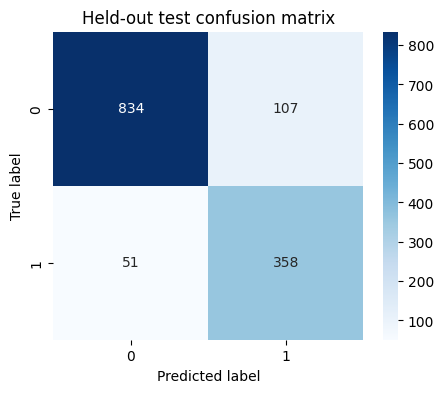

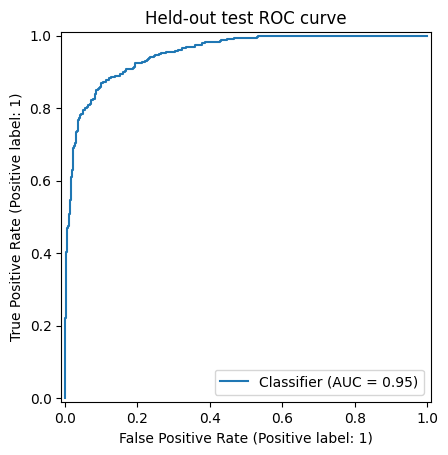

In [43]:
cm = confusion_matrix(y_test, test_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Held-out test confusion matrix")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.show()

RocCurveDisplay.from_predictions(y_test, test_proba)
plt.title("Held-out test ROC curve")
plt.show()


In [44]:
def risk_interpretation_agent(model_score):
    if model_score < 0.33:
        band = "Lower model-score band (demo only)"
    elif model_score < 0.66:
        band = "Middle model-score band (demo only)"
    else:
        band = "Higher model-score band (demo only)"
    return {
        "positive_class_model_score": float(model_score),
        "demo_band": band,
        "clinical_interpretation": "Not established. Requires validated clinical assessment."
    }


,feature,importance_mean,importance_std
12,max_heart_rate_achieved,0.307841,0.024181
15,st_depression,0.026464,0.006233
14,exercise_induced_angina,0.025503,0.005833
0,age,0.016383,0.004050
13,chest_pain_type,0.009757,0.002452
5,hdl,0.007501,0.002111
6,ldl,0.005547,0.001291
9,hba1c,0.005450,0.001901
17,smoker_status,0.004921,0.001079
2,resting_bp_systolic,0.002666,0.001357


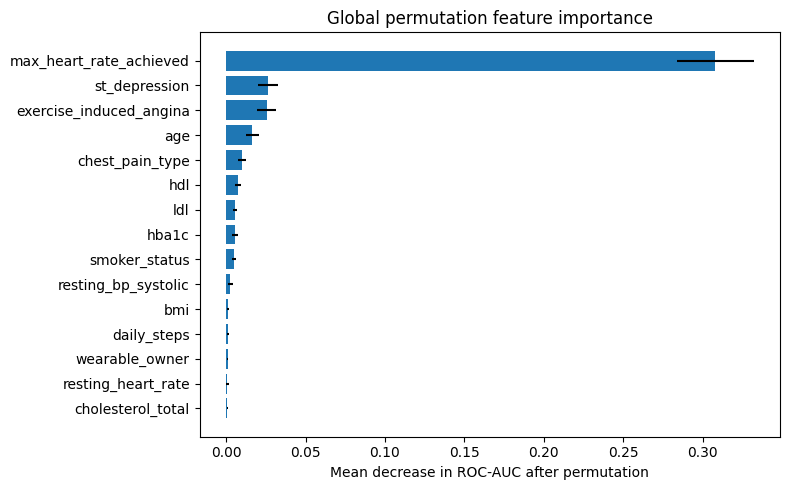

In [45]:
# Use a manageable validation sample for runtime.
X_explain = X_valid.sample(min(300, len(X_valid)), random_state=RANDOM_STATE)
y_explain = y_valid.loc[X_explain.index]

perm = permutation_importance(
    best_model, X_explain, y_explain,
    n_repeats=5, random_state=RANDOM_STATE,
    scoring="roc_auc", n_jobs=-1
)
importance = pd.DataFrame({
    "feature": X.columns,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=False)

display(importance.head(15))
plt.figure(figsize=(8, 5))
top = importance.head(15).sort_values("importance_mean")
plt.barh(top["feature"], top["importance_mean"], xerr=top["importance_std"])
plt.xlabel("Mean decrease in ROC-AUC after permutation")
plt.title("Global permutation feature importance")
plt.tight_layout()
plt.show()


In [46]:
def clinical_evidence_agent():
    return {
        "evidence_source_status": "No external guideline source connected in this prototype",
        "required_next_step": "Clinician reviews current authoritative guidance and patient context",
        "treatment_recommendation": None,
        "safety_note": "The model output must not be used alone for diagnosis or treatment."
    }


In [50]:
def data_intake_agent(dataframe):
    return {
        "rows_received": int(dataframe.shape[0]),
        "columns_received": int(dataframe.shape[1]),
        "missing_cells": int(dataframe.isna().sum().sum()),
        "duplicate_rows": int(dataframe.duplicated().sum())
    }

def preprocessing_agent():
    return {
        "numeric_features": numeric_features,
        "categorical_features": categorical_features,
        "target": TARGET_COLUMN,
        "identifier_columns_excluded": id_like,
        "train_validation_test_rows": [int(len(X_train)), int(len(X_valid)), int(len(X_test))]
    }

def prediction_agent(record):
    score = float(best_model.predict_proba(record)[0, 1])
    pred = int(best_model.predict(record)[0])
    return {"predicted_encoded_class": pred, "positive_class_model_score": score}

def explainability_agent_summary():
    return importance.head(5).to_dict(orient="records")

def report_generation_agent(record_index=0):
    record = X_test.iloc[[record_index]]
    prediction = prediction_agent(record)
    return {
        "workflow": "Agentic AI CDSS educational prototype",
        "record_reference": f"test_row_{record_index}",
        "data_intake_agent": data_intake_agent(raw_df),
        "preprocessing_agent": preprocessing_agent(),
        "prediction_agent": prediction,
        "risk_interpretation_agent": risk_interpretation_agent(prediction["positive_class_model_score"]),
        "explainability_agent": explainability_agent_summary(),
        "clinical_evidence_agent": clinical_evidence_agent(),
        "human_review": {
            "status": "PENDING",
            "final_decision_maker": "Qualified healthcare professional"
        },
        "test_metrics": test_metrics
    }

demo_report = report_generation_agent(0)
print(json.dumps(demo_report, indent=2, default=str))


{
  "workflow": "Agentic AI CDSS educational prototype",
  "record_reference": "test_row_0",
  "data_intake_agent": {
    "rows_received": 9000,
    "columns_received": 27,
    "missing_cells": 0,
    "duplicate_rows": 0
  },
  "preprocessing_agent": {
    "numeric_features": [
      "age",
      "resting_bp_systolic",
      "resting_bp_diastolic",
      "cholesterol_total",
      "hdl",
      "ldl",
      "triglycerides",
      "fasting_blood_sugar",
      "hba1c",
      "bmi",
      "resting_heart_rate",
      "max_heart_rate_achieved",
      "exercise_induced_angina",
      "st_depression",
      "family_history",
      "alcohol_units_per_week",
      "exercise_minutes_per_week",
      "sleep_hours",
      "stress_score",
      "wearable_owner",
      "daily_steps",
      "diet_quality_score"
    ],
    "categorical_features": [
      "sex",
      "chest_pain_type",
      "smoker_status"
    ],
    "target": "has_heart_disease",
    "identifier_columns_excluded": [
      "patient_id

In [48]:
joblib.dump(best_model, ARTIFACT_DIR / "heart_disease_pipeline.joblib")
(ARTIFACT_DIR / "test_metrics.json").write_text(json.dumps(test_metrics, indent=2))
(ARTIFACT_DIR / "agent_demo_report.json").write_text(json.dumps(demo_report, indent=2, default=str))
validation_results.to_csv(ARTIFACT_DIR / "validation_model_comparison.csv", index=False)
importance.to_csv(ARTIFACT_DIR / "permutation_feature_importance.csv", index=False)

metadata = {
    "dataset_file": CSV_PATH,
    "target_column": TARGET_COLUMN,
    "target_classes": [str(x) for x in target_encoder.classes_],
    "feature_columns": list(X.columns),
    "selected_model": selected_name,
    "random_state": RANDOM_STATE,
    "warning": "Educational prototype only; not for clinical use."
}
(ARTIFACT_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2))
print("Saved artifacts:")
for p in sorted(ARTIFACT_DIR.iterdir()):
    print(p.name, p.stat().st_size, "bytes")


Saved artifacts:
agent_demo_report.json 2887 bytes
heart_disease_pipeline.joblib 6714 bytes
metadata.json 833 bytes
permutation_feature_importance.csv 1491 bytes
test_metrics.json 206 bytes
validation_model_comparison.csv 314 bytes


In [49]:
# Download all generated outputs as one ZIP file.
zip_path = "cdss_coursework_artifacts.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for p in ARTIFACT_DIR.iterdir():
        zf.write(p, arcname=f"cdss_artifacts/{p.name}")

from google.colab import files
files.download(zip_path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>